# Exploratory Data Anlysis for Biodegradable ML Project

## Introduction

Here we perform EDA for the QSAR biodegradable dataset. Below we try to first download the dataset using the UCI dataset interface, but it fails. So instead we manually download it from [here](https://archive.ics.uci.edu/dataset/254/qsar+biodegradation?). Our focus in this document will be to answer the following three questions:

1. Is the dataset balanced, and are there any data-quality issues?
2. What do the molecular descriptors look like statistically?
3. Which descriptors appear most informative for predicting biodegradability?

The dataset has 1055 examples, 41 molecular descriptors (features), and our target variable. The target, labeled as column 42 above, will contain only two values:

- eady biodegradable (RB)
- not ready biodegradable (NRB)

Our task in this project is to predict these values


The breakdown of the columns in terms of molecular descriptors from the website is:

41 molecular descriptors and 1 experimental class:
1) SpMax_L: Leading eigenvalue from Laplace matrix
2) J_Dz(e): Balaban-like index from Barysz matrix weighted by Sanderson electronegativity
3) nHM: Number of heavy atoms
4) F01[N-N]: Frequency of N-N at topological distance 1
5) F04[C-N]: Frequency of C-N at topological distance 4
6) NssssC: Number of atoms of type ssssC
7) nCb-: Number of substituted benzene C(sp2)
8) C%: Percentage of C atoms
9) nCp: Number of terminal primary C(sp3)
10) nO: Number of oxygen atoms
11) F03[C-N]: Frequency of C-N at topological distance 3
12) SdssC: Sum of dssC E-states
13) HyWi_B(m): Hyper-Wiener-like index (log function) from Burden matrix weighted by mass
14) LOC: Lopping centric index
15) SM6_L: Spectral moment of order 6 from Laplace matrix
16) F03[C-O]: Frequency of C - O at topological distance 3
17) Me: Mean atomic Sanderson electronegativity (scaled on Carbon atom)
18) Mi: Mean first ionization potential (scaled on Carbon atom)
19) nN-N: Number of N hydrazines
20) nArNO2: Number of nitro groups (aromatic)
21) nCRX3: Number of CRX3
22) SpPosA_B(p): Normalized spectral positive sum from Burden matrix weighted by polarizability
23) nCIR: Number of circuits
24) B01[C-Br]: Presence/absence of C - Br at topological distance 1
25) B03[C-Cl]: Presence/absence of C - Cl at topological distance 3
26) N-073: Ar2NH / Ar3N / Ar2N-Al / R..N..R
27) SpMax_A: Leading eigenvalue from adjacency matrix (Lovasz-Pelikan index)
28) Psi_i_1d: Intrinsic state pseudoconnectivity index - type 1d
29) B04[C-Br]: Presence/absence of C - Br at topological distance 4
30) SdO: Sum of dO E-states
31) TI2_L: Second Mohar index from Laplace matrix
32) nCrt: Number of ring tertiary C(sp3)
33) C-026: R--CX--R
34) F02[C-N]: Frequency of C - N at topological distance 2
35) nHDon: Number of donor atoms for H-bonds (N and O)
36) SpMax_B(m): Leading eigenvalue from Burden matrix weighted by mass
37) Psi_i_A: Intrinsic state pseudoconnectivity index - type S average
38) nN: Number of Nitrogen atoms
39) SM6_B(m): Spectral moment of order 6 from Burden matrix weighted by mass
40) nArCOOR: Number of esters (aromatic)
41) nX: Number of halogen atoms
42) experimental class: ready biodegradable (RB) and not ready biodegradable (NRB)


## Imports & Data Loading

In [2]:
# imports & data downloads

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#NOTE: the below import failed - seems to be an issue with the API? In any case, we can
#from ucimlrepo import fetch_ucirepo
# Download QSAR Biodegradation dataset
#dataset = fetch_ucirepo(id=254)


In [11]:
#load dataset & implement correct feature labels
feature_names = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]",
    "NssssC", "nCb-", "C%", "nCp", "nO",
    "F03[C-N]", "SdssC", "HyWi_B(m)", "LOC", "SM6_L",
    "F03[C-O]", "Me", "Mi", "nN-N", "nArNO2",
    "nCRX3", "SpPosA_B(p)", "nCIR", "B01[C-Br]",
    "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d",
    "B04[C-Br]", "SdO", "TI2_L", "nCrt",
    "C-026", "F02[C-N]", "nHDon", "SpMax_B(m)",
    "Psi_i_A", "nN", "SM6_B(m)", "nArCOOR", "nX"
]

df = pd.read_csv(
    "../data/biodeg.csv",
    sep=";",
    header=None,
    names=feature_names + ["biodegradable"]
)


print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1055, 42)


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,biodegradable
0,3.919,2.6909,0,0,0,0,0,31.4,2,0,...,0,0,0,2.949,1.591,0,7.253,0,0,RB
1,4.170,2.1144,0,0,0,0,0,30.8,1,1,...,0,0,0,3.315,1.967,0,7.257,0,0,RB
2,3.932,3.2512,0,0,0,0,0,26.7,2,4,...,0,0,1,3.076,2.417,0,7.601,0,0,RB
3,3.000,2.7098,0,0,0,0,0,20.0,0,2,...,0,0,1,3.046,5.000,0,6.690,0,0,RB
4,4.236,3.3944,0,0,0,0,0,29.4,2,4,...,0,0,0,3.351,2.405,0,8.003,0,0,RB


## Features & Target

In [49]:
# separate input features and target
X = df[feature_names]
y = df["biodegradable"]

# map target to binary variables
y_binary = y.map({"NRB": 0, "RB": 1})

print(y_binary.value_counts())

print("Features:", X.shape)
print("Target:", y.shape)

biodegradable
0    699
1    356
Name: count, dtype: int64
Features: (1055, 41)
Target: (1055,)


## Data Verification, update features & target

We find that there are no mising values, and we examine some statistics.

We also check for duplicate values, and find some.

In [14]:
print("Missing values:", df.isna().sum().sum())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nClass proportions:")
print(y.value_counts(normalize=True))

print("\nSummary statistics:")
display(X.describe())

Missing values: 0

Data types:
int64      24
float64    17
str         1
Name: count, dtype: int64

Class proportions:
biodegradable
NRB    0.662559
RB     0.337441
Name: proportion, dtype: float64

Summary statistics:


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,nCrt,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX
count,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,...,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000,1055.000000
mean,4.782644,3.069508,0.716588,0.042654,0.980095,0.290047,1.646445,37.055640,1.376303,1.803791,...,0.129858,0.883412,1.274882,0.961137,3.918240,2.558417,0.686256,8.629492,0.051185,0.723223
std,0.546916,0.831308,1.462452,0.256010,2.332955,1.073771,2.224822,9.144466,1.963521,1.775435,...,0.644057,1.520467,2.273994,1.257013,0.999602,0.642765,1.090389,1.241986,0.318970,2.239286
min,2.000000,0.803900,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2.267000,1.467000,0.000000,4.917000,0.000000,0.000000
25%,4.481000,2.502750,0.000000,0.000000,0.000000,0.000000,0.000000,30.450000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,3.487500,2.103000,0.000000,7.991000,0.000000,0.000000
50%,4.828000,3.046300,0.000000,0.000000,0.000000,0.000000,1.000000,37.500000,1.000000,2.000000,...,0.000000,0.000000,0.000000,1.000000,3.726000,2.458000,0.000000,8.499000,0.000000,0.000000
75%,5.125000,3.437650,1.000000,0.000000,1.000000,0.000000,3.000000,43.400000,2.000000,3.000000,...,0.000000,1.000000,2.000000,2.000000,3.987000,2.870500,1.000000,9.020500,0.000000,0.000000
max,6.496000,9.177500,12.000000,3.000000,36.000000,13.000000,18.000000,60.700000,24.000000,12.000000,...,8.000000,12.000000,18.000000,7.000000,10.695000,5.825000,8.000000,14.700000,4.000000,27.000000


In [58]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate feature vectors:", X.duplicated().sum())

Duplicate rows: 3
Duplicate feature vectors: 3


In [59]:
# Show all rows with duplicated feature vectors
duplicates = df[df.duplicated(subset=feature_names, keep=False)]

display(duplicates.sort_values(by=feature_names))

,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,biodegradable
132,4.343,3.9399,0,0,0,0,0,33.3,0,4,...,0,0,2,3.519,4.167,0,8.016,0,0,RB
196,4.343,3.9399,0,0,0,0,0,33.3,0,4,...,0,0,2,3.519,4.167,0,8.016,0,0,RB
178,4.983,4.2631,0,0,0,0,0,23.1,2,6,...,0,0,6,3.397,3.694,0,7.880,0,0,RB
268,4.983,4.2631,0,0,0,0,0,23.1,2,6,...,0,0,6,3.397,3.694,0,7.880,0,0,RB
299,5.998,1.8789,6,0,0,3,0,44.4,0,1,...,0,0,0,4.405,2.355,0,9.843,0,6,NRB
910,5.998,1.8789,6,0,0,3,0,44.4,0,1,...,0,0,0,4.405,2.355,0,9.843,0,6,NRB


In [60]:
# Count distinct labels associated with each feature vector
label_counts = (
    df.groupby(feature_names)["biodegradable"]
    .nunique()
)

conflicting_labels = label_counts[label_counts > 1]

print("Feature vectors with conflicting labels:", len(conflicting_labels))

Feature vectors with conflicting labels: 0


In [61]:
df = df.drop_duplicates().reset_index(drop=True)

print("New dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

New dataset shape: (1052, 42)
Remaining duplicates: 0


In [62]:
X = df.drop(columns=["biodegradable"])
y = df["biodegradable"]

y_binary = y.map({
    "NRB": 0,
    "RB": 1
})

print(X.shape, y.shape)

(1052, 41) (1052,)


## Feature Division

### Discussion

We can see from the above that we have 3 types of features in our dataset:

- continuous numerical
- discrete numerical
- categorical

The difference between categorical and discrete numerical data belongs to an ordered set whereas categorical data does not. We can also separate out binary indicators from other types of categorical data. We find the divisions as:

In [33]:
# Binary indicators
binary_features = [
    "B01[C-Br]",
    "B03[C-Cl]",
    "B04[C-Br]"
]

# Discrete numerical descriptors
discrete_features = [
    "nHM", "F01[N-N]", "F04[C-N]", "NssssC",
    "nCb-", "nCp", "nO", "F03[C-N]",
    "F03[C-O]", "nN-N", "nArNO2", "nCRX3",
    "nCIR", "N-073", "nCrt", "C-026",
    "F02[C-N]", "nHDon", "nN",
    "nArCOOR", "nX"
]

# Remaining continuous numerical descriptors
continuous_features = [
    col for col in feature_names
    if col not in binary_features + discrete_features
]

print("Binary:", len(binary_features))
print("Discrete:", len(discrete_features))
print("Continuous:", len(continuous_features))

Binary: 3
Discrete: 21
Continuous: 17


### Code

In [15]:
#check number of unique values
feature_summary = pd.DataFrame({
    "dtype": X.dtypes,
    "n_unique": X.nunique(),
    "min": X.min(),
    "max": X.max()
})

display(feature_summary)

,dtype,n_unique,min,max
SpMax_L,float64,440,2.0000,6.4960
J_Dz(e),float64,1022,0.8039,9.1775
nHM,int64,11,0.0000,12.0000
F01[N-N],int64,4,0.0000,3.0000
F04[C-N],int64,16,0.0000,36.0000
NssssC,int64,13,0.0000,13.0000
nCb-,int64,15,0.0000,18.0000
C%,float64,188,0.0000,60.7000
nCp,int64,15,0.0000,24.0000
nO,int64,12,0.0000,12.0000


In [16]:
# identify binary indicators
binary_features = [
    col for col in X.columns
    if set(X[col].dropna().unique()).issubset({0, 1})
]

print("Binary features:", binary_features)

Binary features: ['B01[C-Br]', 'B03[C-Cl]', 'B04[C-Br]']


In [17]:
integer_valued_features = [
    col for col in X.columns
    if np.all(np.isclose(X[col].dropna() % 1, 0))
]

print("Integer-valued features:", integer_valued_features)

Integer-valued features: ['nHM', 'F01[N-N]', 'F04[C-N]', 'NssssC', 'nCb-', 'nCp', 'nO', 'F03[C-N]', 'F03[C-O]', 'nN-N', 'nArNO2', 'nCRX3', 'nCIR', 'B01[C-Br]', 'B03[C-Cl]', 'N-073', 'B04[C-Br]', 'nCrt', 'C-026', 'F02[C-N]', 'nHDon', 'nN', 'nArCOOR', 'nX']


In [18]:
other_numerical_features = [
    col for col in X.columns
    if col not in integer_valued_features
]

## Question #1: Class distribution

### Discussion

In the code below, we see that we do indeed has a class imbalance: about a third of our samples are RB, and the remaining two-thirds are NRB. This is not an extreme imbalance, but enough that we should not use accuracy as an ideal evaluation metric in our ML approach. Instead we will primarily use ROC-AUC supplemented by precision, recall, and F1.

### Code

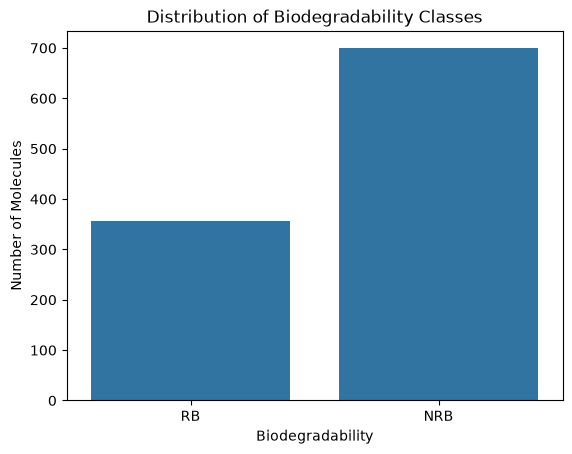

Fraction of RB: 0.33744075829383885
Fraction of NRB: 0.6625592417061611


In [31]:
sns.countplot(data=df, x="biodegradable")
plt.title("Distribution of Biodegradability Classes")
plt.xlabel("Biodegradability")
plt.ylabel("Number of Molecules")
plt.show()

num_RB = df[df.biodegradable == "RB"].shape[0]
num_NRB = df[df.biodegradable == "NRB"].shape[0]

print("Fraction of RB:",num_RB/(num_RB+num_NRB ) )
print("Fraction of NRB:",num_NRB/(num_RB+num_NRB ) )

## Question #2: Feature Distributions

### Discussion

We address Question #2 above and look at the distributions of the features. Recall that above we divided the features into 3 categories. We examine each of these in turn.


From the continuous data plots below, we see that a number of the histograms are skewed, but none of the have particularly long tails.

### Plots

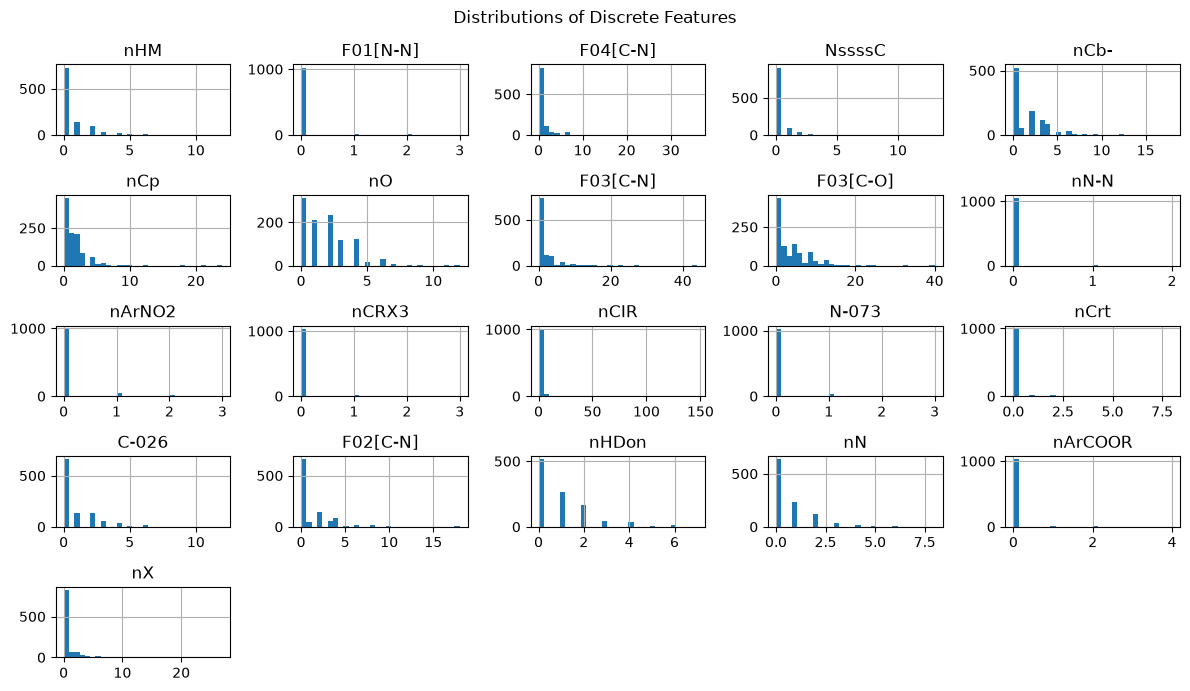

In [34]:
# discrete numerical feature plots
X[discrete_features].hist(
    bins=30,
    figsize=(12, 7)
)

plt.suptitle("Distributions of Discrete Features")
plt.tight_layout()
plt.show()

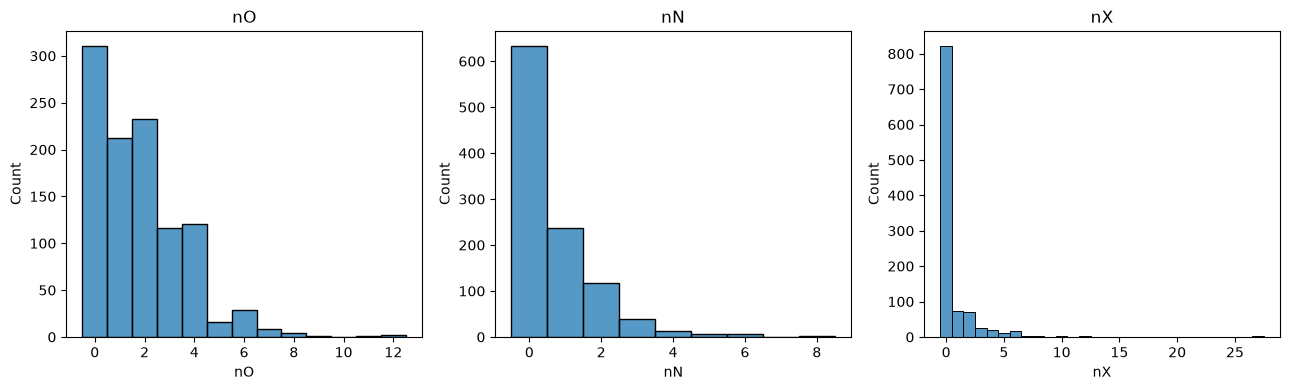

In [40]:
# subset of discrete feature plots
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col in zip(axes, ["nO", "nN", "nX"]):
    sns.histplot(
        data=df,
        x=col,
        discrete=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

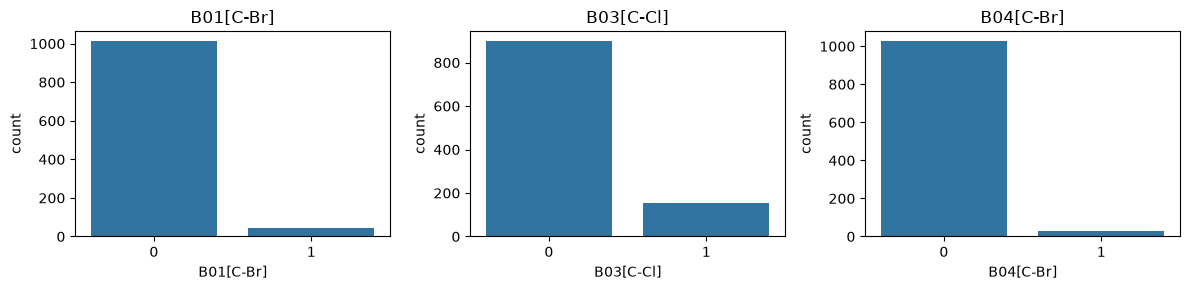

In [39]:
# binary indicator plots
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, col in zip(axes, binary_features):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

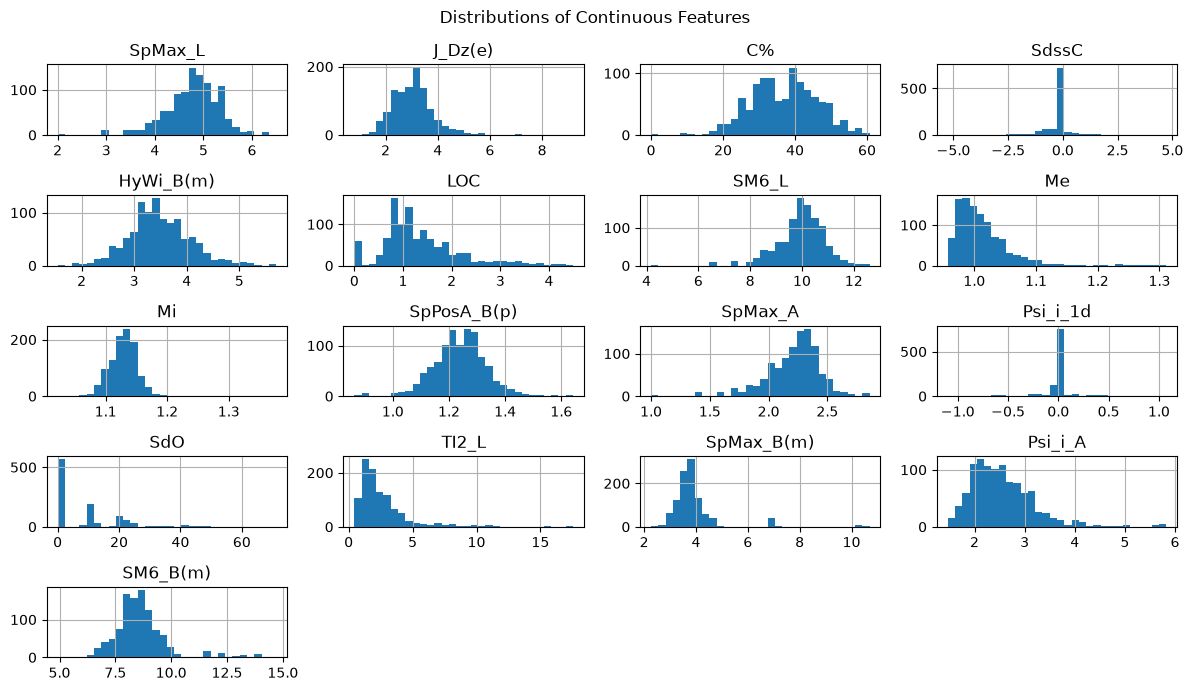

In [44]:
#continuous feature plots
X[continuous_features].hist(
    bins=30,
    figsize=(12, 7)
)

plt.suptitle("Distributions of Continuous Features")
plt.tight_layout()
plt.show()

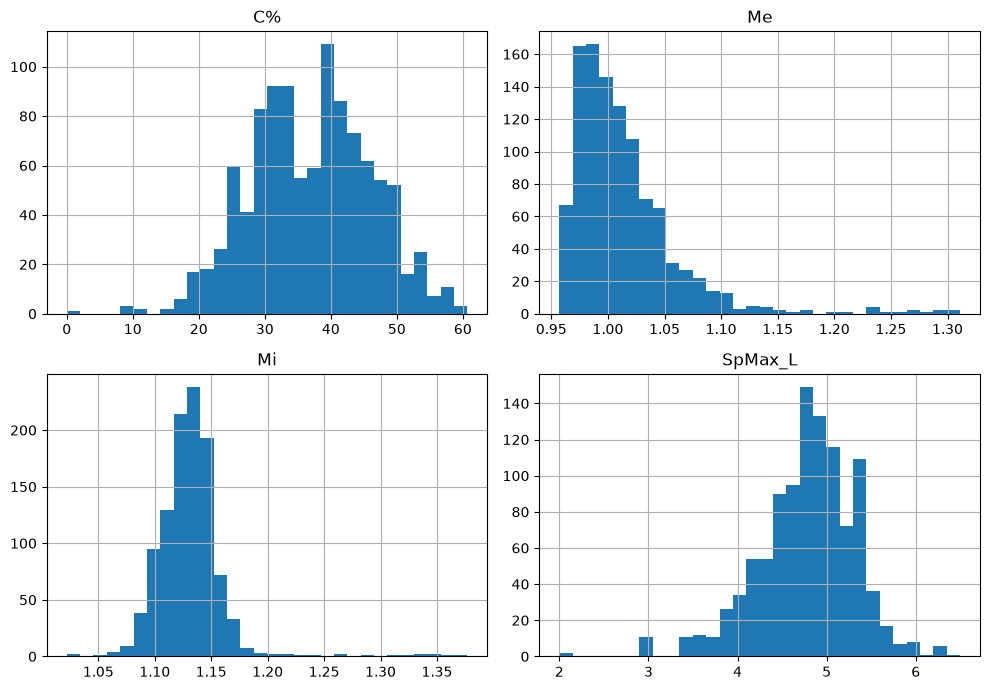

In [42]:
# subset of continuous feature plots
selected_continuous = ["C%", "Me", "Mi", "SpMax_L"]

df[selected_continuous].hist(
    bins=30,
    figsize=(10, 7)
)

plt.tight_layout()
plt.show()

## Question #3: Feature Importance

### Discussion

From the data analysis below, we find evidence for the following statements:

1. **Topological Features may be important**:
    The strongest correlators with biodegradability are, in order: {SpMax_L,SpMax_A,SpPosA_B(p),SM6_B(m),HyWi_B(m),SM6_L,nCb-,C-026}. Six of these involve spectral or graph-      related molecular descriptors. This suggests that larger values are associated with a lower frequency of biodegradable compounds.
2. **Several features are highly redundant**: The feature pairs {(SM6_L,SpMax_A),(SpMax_L,SpMax_A), (SpMax_B(m),SM6_B(m)),(SpMax_L,SM6_L),(F04[C-N],F03[C-N]),(nO / F03[C-O])}
    all have highPearson correlation coefficients. This suggests a high level of redundancy that can impact training later. We may want to remove one from each pair later.
3. **Mutual information contains a surprise**:
    The mutual information of the feature SdO has a mutual information of .102, but Pearson correlation 0.054 with biodegradability. This suggests that SdO may have a non-
    linear or non-monotonic association with biodegradability.

### Correlations

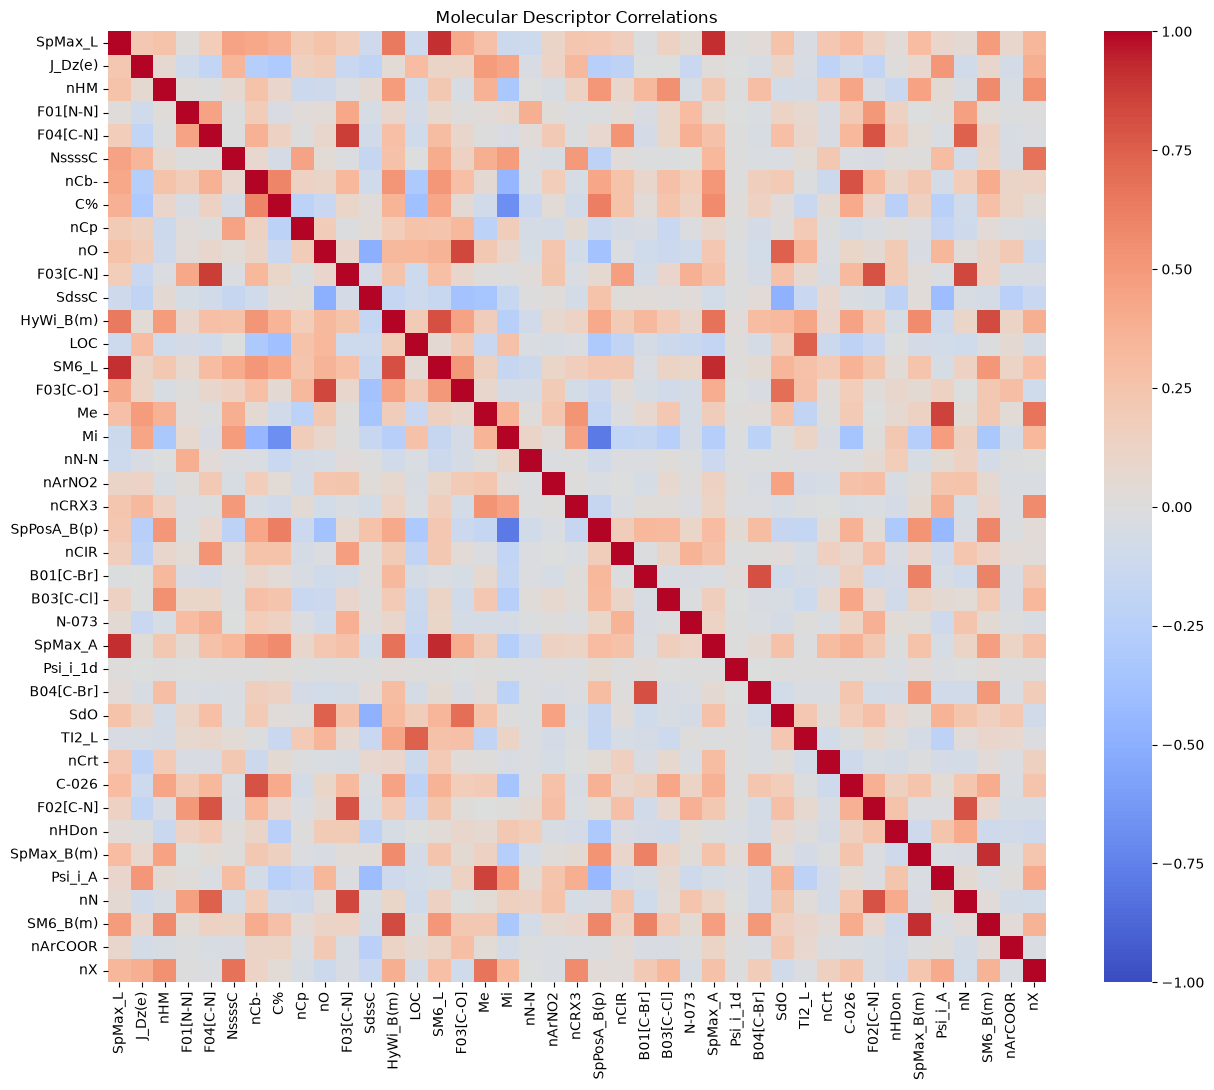

In [50]:
# calculate Pearson correlation matrix

corr_matrix = X.corr()

plt.figure(figsize=(13, 11))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Molecular Descriptor Correlations")
plt.tight_layout()
plt.show()

In [53]:
# Keep only the upper triangle, excluding the diagonal
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

strong_pairs = (
    upper.stack()
    .rename("correlation")
    .reset_index()
)

strong_pairs.columns = ["feature_1", "feature_2", "correlation"]

strong_pairs["abs_corr"] = strong_pairs["correlation"].abs()

strong_pairs = strong_pairs.sort_values(
    "abs_corr", ascending=False
)

display(strong_pairs.head(10))

,feature_1,feature_2,correlation,abs_corr
600,SM6_L,SpMax_A,0.922649,0.922649
26,SpMax_L,SpMax_A,0.918928,0.918928
1473,SpMax_B(m),SM6_B(m),0.917443,0.917443
14,SpMax_L,SM6_L,0.911546,0.911546
174,F04[C-N],F03[C-N],0.870518,0.870518
692,Me,Psi_i_A,0.853752,0.853752
384,nO,F03[C-O],0.840137,0.840137
447,F03[C-N],nN,0.837190,0.837190
530,HyWi_B(m),SM6_B(m),0.821144,0.821144
971,B01[C-Br],B04[C-Br],0.810912,0.810912


In [51]:
# examine point-biserial correlation

target_corr = X.corrwith(y_binary)

target_corr = target_corr.sort_values(
    key=abs,
    ascending=False
)

display(target_corr.head(15))

SpMax_L       -0.396138
SpMax_A       -0.389951
SpPosA_B(p)   -0.372254
SM6_B(m)      -0.366793
HyWi_B(m)     -0.343779
SM6_L         -0.343377
nCb-          -0.337268
C-026         -0.318547
nHM           -0.299107
SpMax_B(m)    -0.289619
LOC            0.275321
F02[C-N]      -0.268875
nN            -0.261751
B03[C-Cl]     -0.252103
F03[C-N]      -0.242325
dtype: float64

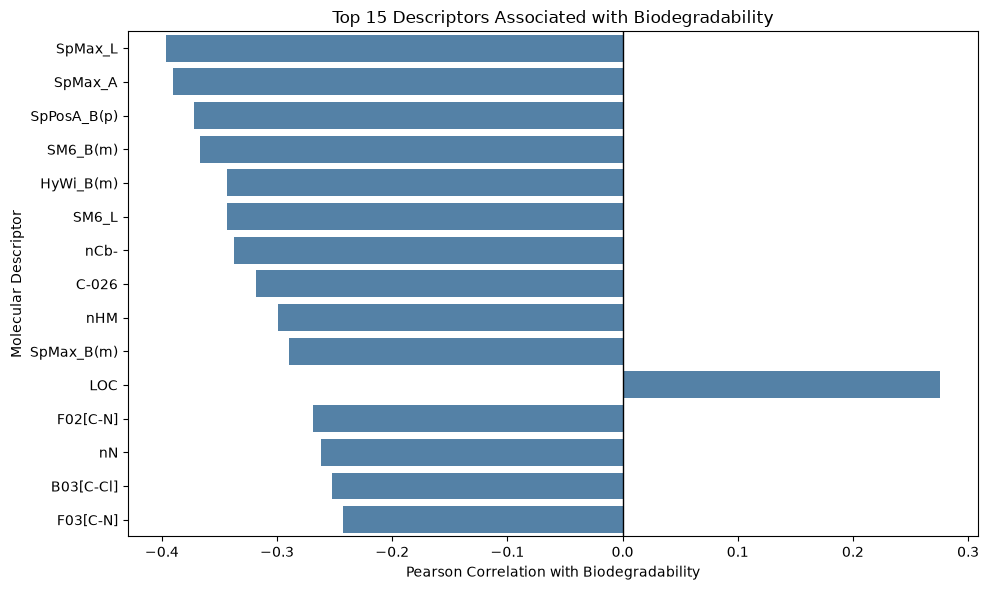

In [52]:
top_corr = target_corr.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_corr.values,
    y=top_corr.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Pearson Correlation with Biodegradability")
plt.ylabel("Molecular Descriptor")
plt.title("Top 15 Descriptors Associated with Biodegradability")
plt.tight_layout()
plt.show()

### Mutual Information

In [54]:
from sklearn.feature_selection import mutual_info_classif

# Integer count descriptors and binary indicators are discrete
discrete_mask = X.columns.isin(
    binary_features + discrete_features
)

mi_values = mutual_info_classif(
    X,
    y_binary,
    discrete_features=discrete_mask,
    random_state=42
)

mi_scores = pd.Series(
    mi_values,
    index=X.columns
).sort_values(ascending=False)

display(mi_scores.head(15))

SpMax_B(m)     0.176881
SpMax_L        0.147648
SpPosA_B(p)    0.140793
SM6_L          0.125131
SpMax_A        0.124614
SM6_B(m)       0.107710
SdO            0.101834
LOC            0.099186
nCb-           0.090652
HyWi_B(m)      0.082373
nHM            0.081647
C-026          0.079719
nCIR           0.072966
Mi             0.068991
nX             0.068059
dtype: float64

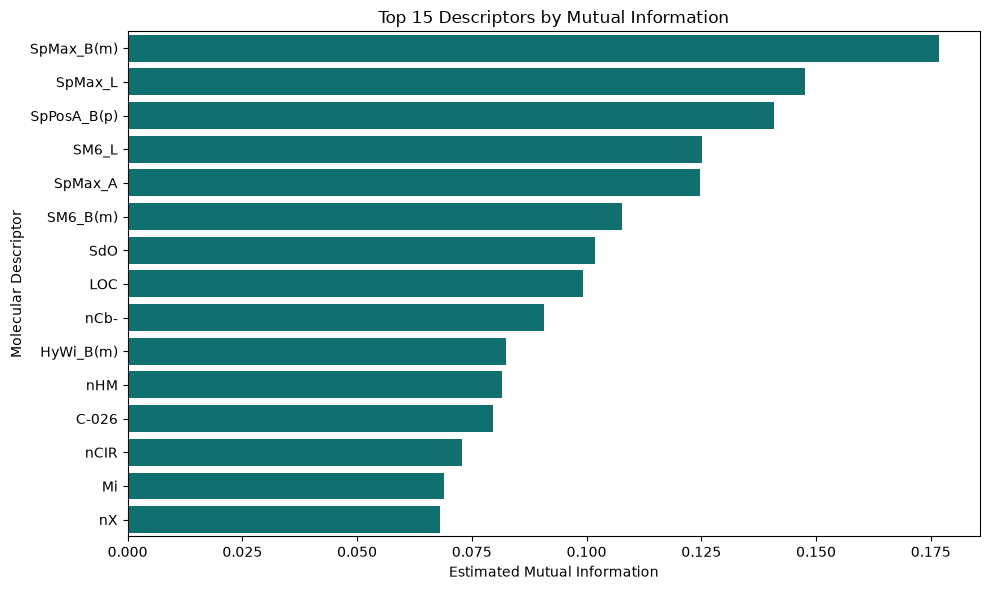

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=mi_scores.head(15).values,
    y=mi_scores.head(15).index,
    color="teal"
)

plt.xlabel("Estimated Mutual Information")
plt.ylabel("Molecular Descriptor")
plt.title("Top 15 Descriptors by Mutual Information")
plt.tight_layout()
plt.show()

### Comparisons

In [56]:
importance_df = pd.DataFrame({
    "correlation": target_corr,
    "abs_correlation": target_corr.abs(),
    "mutual_information": mi_scores
})

importance_df = importance_df.sort_values(
    "mutual_information",
    ascending=False
)

display(importance_df.head(15))

,correlation,abs_correlation,mutual_information
SpMax_B(m),-0.289619,0.289619,0.176881
SpMax_L,-0.396138,0.396138,0.147648
SpPosA_B(p),-0.372254,0.372254,0.140793
SM6_L,-0.343377,0.343377,0.125131
SpMax_A,-0.389951,0.389951,0.124614
SM6_B(m),-0.366793,0.366793,0.107710
SdO,0.053636,0.053636,0.101834
LOC,0.275321,0.275321,0.099186
nCb-,-0.337268,0.337268,0.090652
HyWi_B(m),-0.343779,0.343779,0.082373


### Boxplots

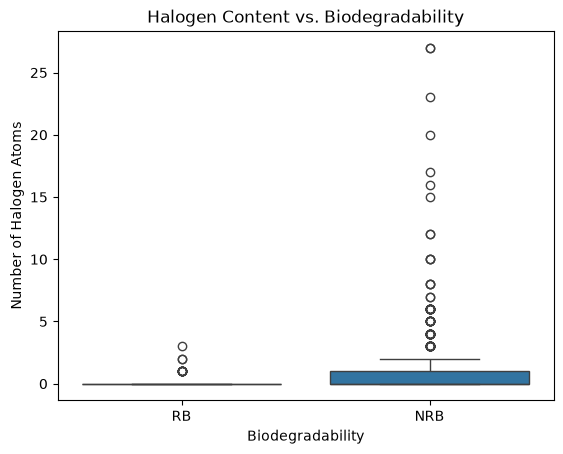

In [45]:
sns.boxplot(
    data=df,
    x="biodegradable",
    y="nX"
)

plt.xlabel("Biodegradability")
plt.ylabel("Number of Halogen Atoms")
plt.title("Halogen Content vs. Biodegradability")
plt.show()

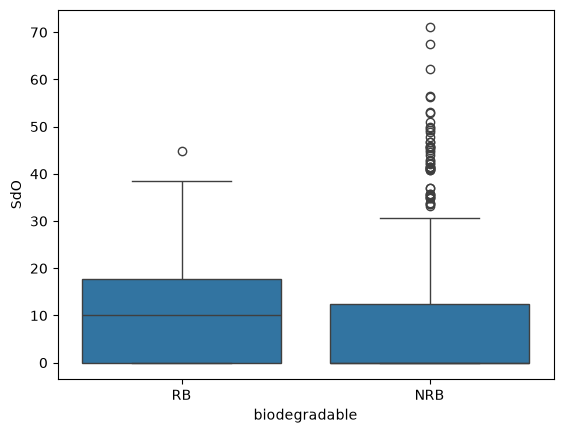

In [57]:
sns.boxplot(
    data=df,
    x="biodegradable",
    y="SdO"
)
plt.show()

In [63]:
df_plot = df.copy()
df_plot["RB"] = y_binary

df_plot["SdO_bin"] = pd.qcut(
    df_plot["SdO"],
    q=8,
    duplicates="drop"
)

df_plot.groupby(
    "SdO_bin",
    observed=True
)["RB"].agg(["mean", "count"])

,mean,count
SdO_bin,,
"(-0.001, 10.345]",0.308980,657
"(10.345, 12.45]",0.462121,132
"(12.45, 22.247]",0.389313,131
"(22.247, 71.167]",0.295455,132


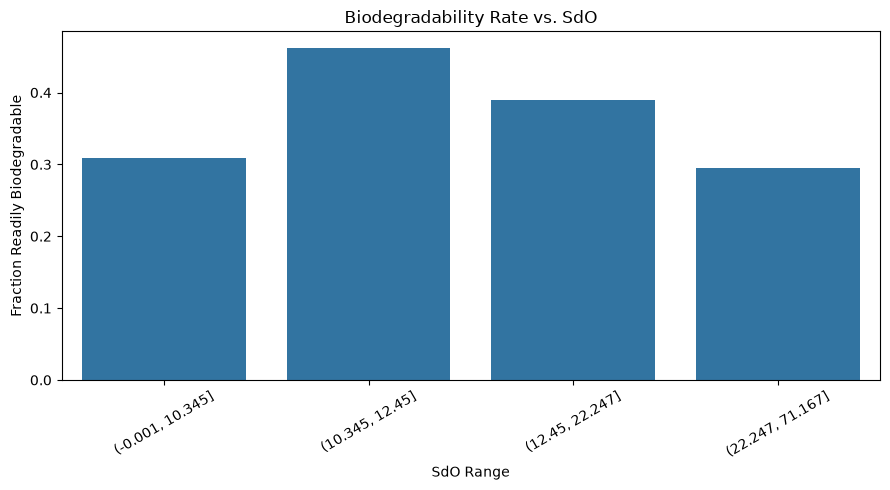

In [64]:
sdo_summary = (
    df_plot.groupby("SdO_bin", observed=True)["RB"]
    .agg(["mean", "count"])
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=sdo_summary,
    x="SdO_bin",
    y="mean"
)

plt.ylabel("Fraction Readily Biodegradable")
plt.xlabel("SdO Range")
plt.title("Biodegradability Rate vs. SdO")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Conclusion

### EDA Summary and Main Findings

The QSAR Biodegradation dataset originally contained 1,055 compounds represented by 41 numerical molecular descriptors, with no missing values. Three duplicate observations were identified and removed, leaving **1,052 unique observations**. The target exhibits moderate class imbalance, with approximately 34% of compounds classified as readily biodegradable (RB) and 66% as not readily biodegradable (NRB).

**1. Feature correlations and molecular structure**

Several molecular descriptors are strongly correlated, particularly those encoding spectral and topological properties of molecular graphs. This suggests substantial redundancy among some features and motivates the use of regularized linear models alongside nonlinear classifiers.

The strongest individual correlations with biodegradability are predominantly negative and involve spectral descriptors such as `SpMax_L`, `SpMax_A`, and `SpPosA_B(p)`. These results suggest that molecular structural and topological information is useful for distinguishing the two classes.

**2. Nonlinear associations and mutual information**

Mutual-information analysis revealed potentially nonlinear relationships that are not captured by Pearson correlation.

A particularly interesting example is `SdO`, which exhibits a very weak linear correlation with biodegradability (\(r \approx 0.054\)) but comparatively high estimated mutual information (\(I \approx 0.102\)).

Binning `SdO` reveals a non-monotonic relationship with biodegradability. The observed fraction of readily biodegradable compounds increases from approximately 31% at low `SdO` values to 46% at intermediate values, before decreasing to approximately 30% at the highest values.

This suggests that `SdO` contains potentially useful nonlinear predictive information. However, the distribution includes many tied values and a long upper tail, so the precise shape of this relationship should be interpreted cautiously.

**3. Chemical composition and biodegradability**

Halogen content (`nX`) is negatively correlated with ready biodegradability (\(r \approx -0.214\)). Non-readily biodegradable compounds also exhibit a broader distribution of halogen counts, including several extreme values.

This is consistent with the possibility that halogen substitution is associated with increased chemical persistence. However, the observed statistical relationship does not establish causality, and the effect likely depends on additional molecular characteristics.

**4. Implications for model development**

The EDA suggests that both molecular composition and graph-theoretic structural descriptors contain useful information for predicting biodegradability.

Given the strong correlations between several predictors, we will initially retain all 41 descriptors and use regularization where appropriate rather than removing correlated features prematurely.

The nonlinear associations identified through mutual information, particularly for `SdO`, motivate comparing logistic regression with nonlinear classifiers such as decision trees, random forests, and gradient-boosted trees.

We will use a stratified train/validation/test split, with ROC-AUC as the primary evaluation metric, supplemented by precision, recall, F1-score, and confusion matrices.

Finally, all preprocessing and supervised feature-selection procedures will be fitted using training data only to prevent information leakage. The test set will be reserved for the final model evaluation.